# 02 · Exploratory patterns in published records

Explore what the workbook encodes after exact duplicate removal. Each chart describes the published rows. Compare field definitions and coverage before interpreting their apparent patterns.

[Previous](01_source_quality_and_cleaning.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](03_statistics_and_identity_sensitivity.ipynb)

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/bd_safety").is_dir(), (
    "Open from the project root or notebooks directory."
)
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"


DB_URI = (ROOT / "data/processed/accident_records.sqlite3").as_uri() + "?mode=ro"

## What do the month and hour fields measure?

Run the verified month query, which keeps each month basis separate. Inspect those distributions alongside hours extracted from the original time field.

-- Report both month fields independently; neither is silently corrected using the other.
SELECT 'Month column' AS basis, declared_month AS month, COUNT(*) AS records
FROM records WHERE declared_month IS NOT NULL GROUP BY declared_month
UNION ALL
SELECT 'Parsed Date' AS basis, date_month AS month, COUNT(*) AS records
FROM records WHERE date_month IS NOT NULL GROUP BY date_month;



basis
Month column    47676
Parsed Date     47533
Name: records, dtype: int64

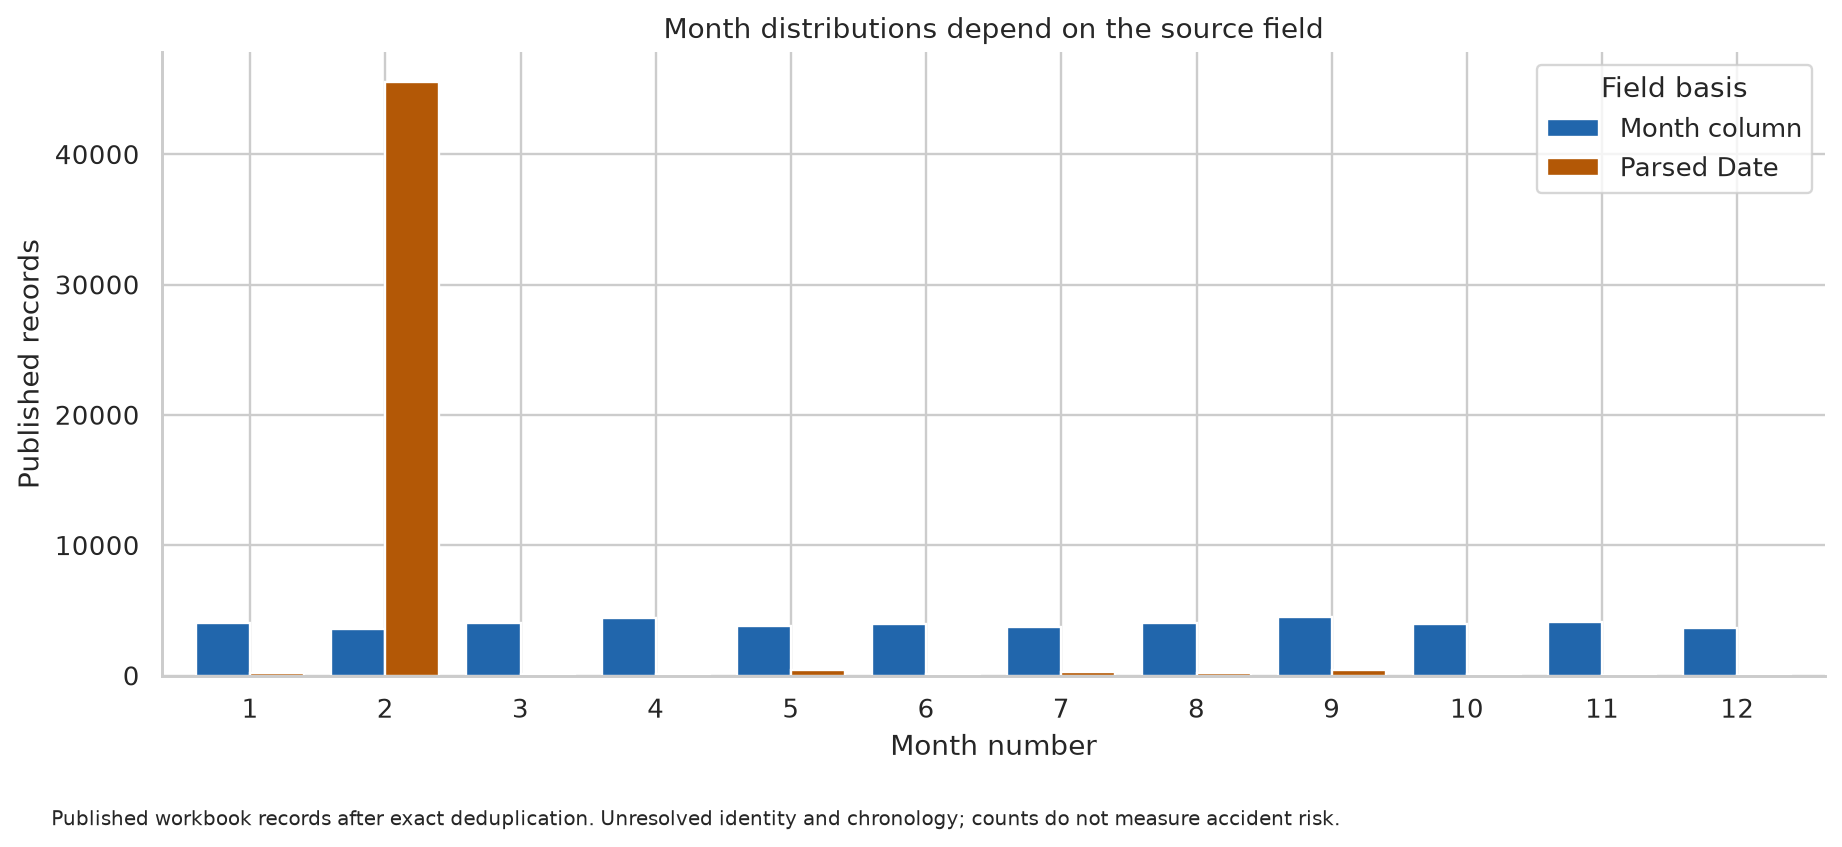

In [2]:
month_sql = (ROOT / "sql/04_months.sql").read_text()
print(month_sql)
with closing(sqlite3.connect(DB_URI, uri=True)) as connection:
    months = pd.read_sql_query(month_sql, connection)
display(months.groupby("basis")["records"].sum())
display(Image(filename=str(REPORTS / "figures/02_month_fields.png"), width=900))

The two month fields place records in different months and have different denominators. Chronology conflicts prevent seasonal inference.

## How concentrated is the recorded hour?

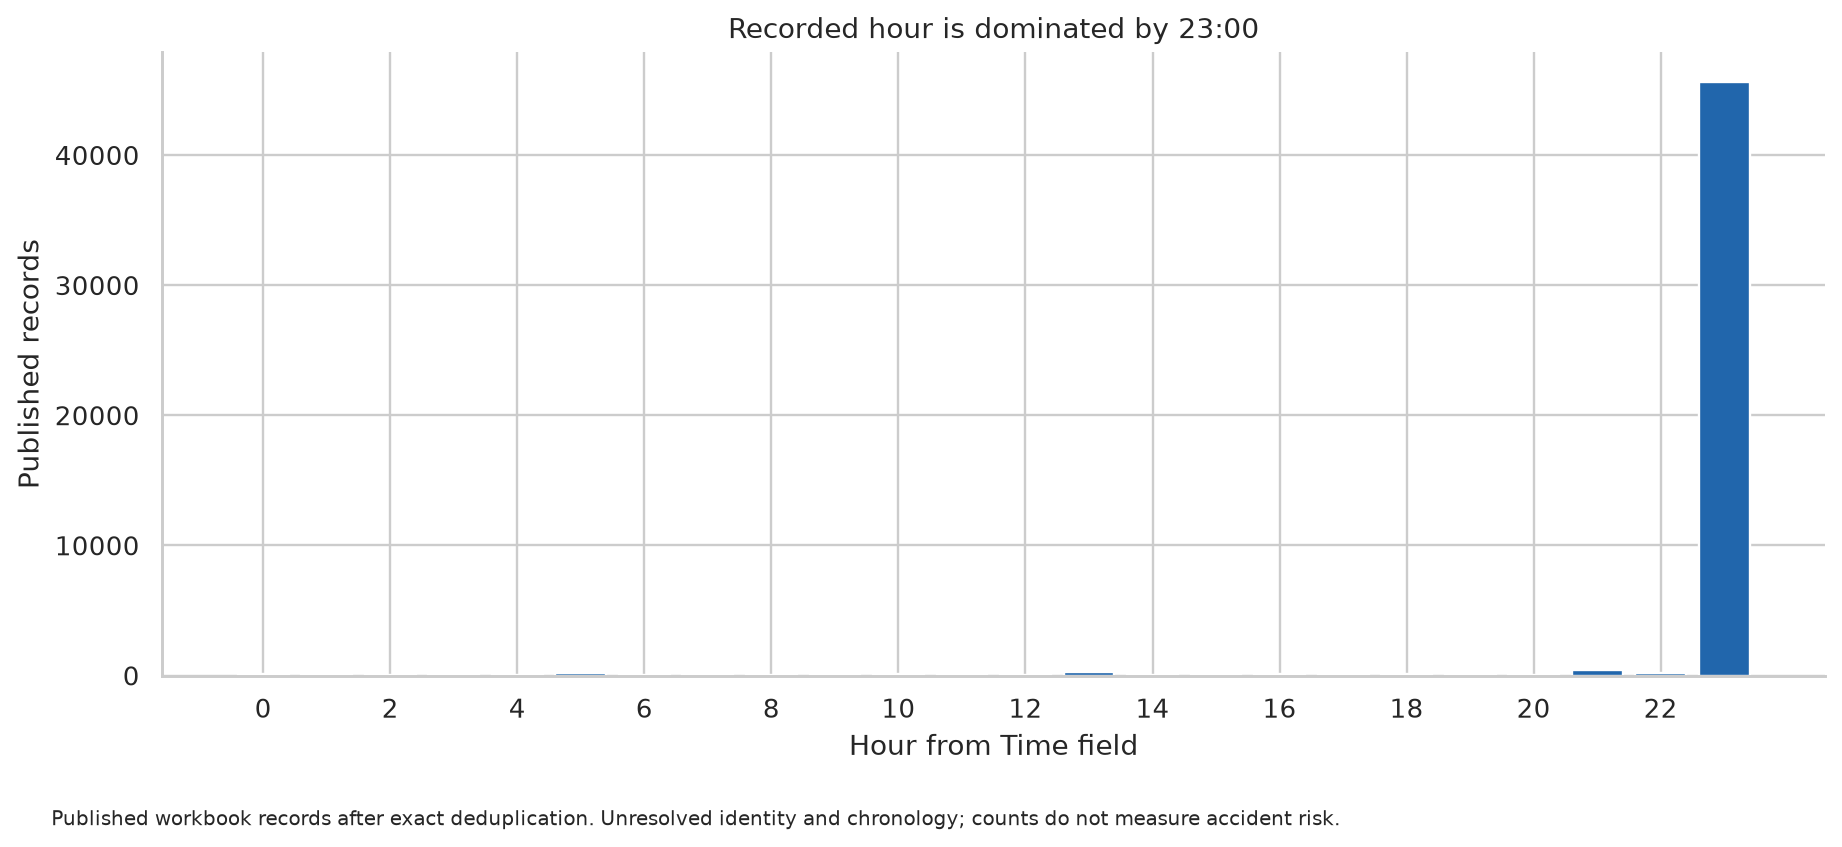

In [3]:
display(Image(filename=str(REPORTS / "figures/03_recorded_hour.png"), width=900))

One recorded time dominates the workbook. Repeated descriptors and unknown traffic exposure limit interpretation of that peak.

## Do severity labels agree with numeric fatality counts?

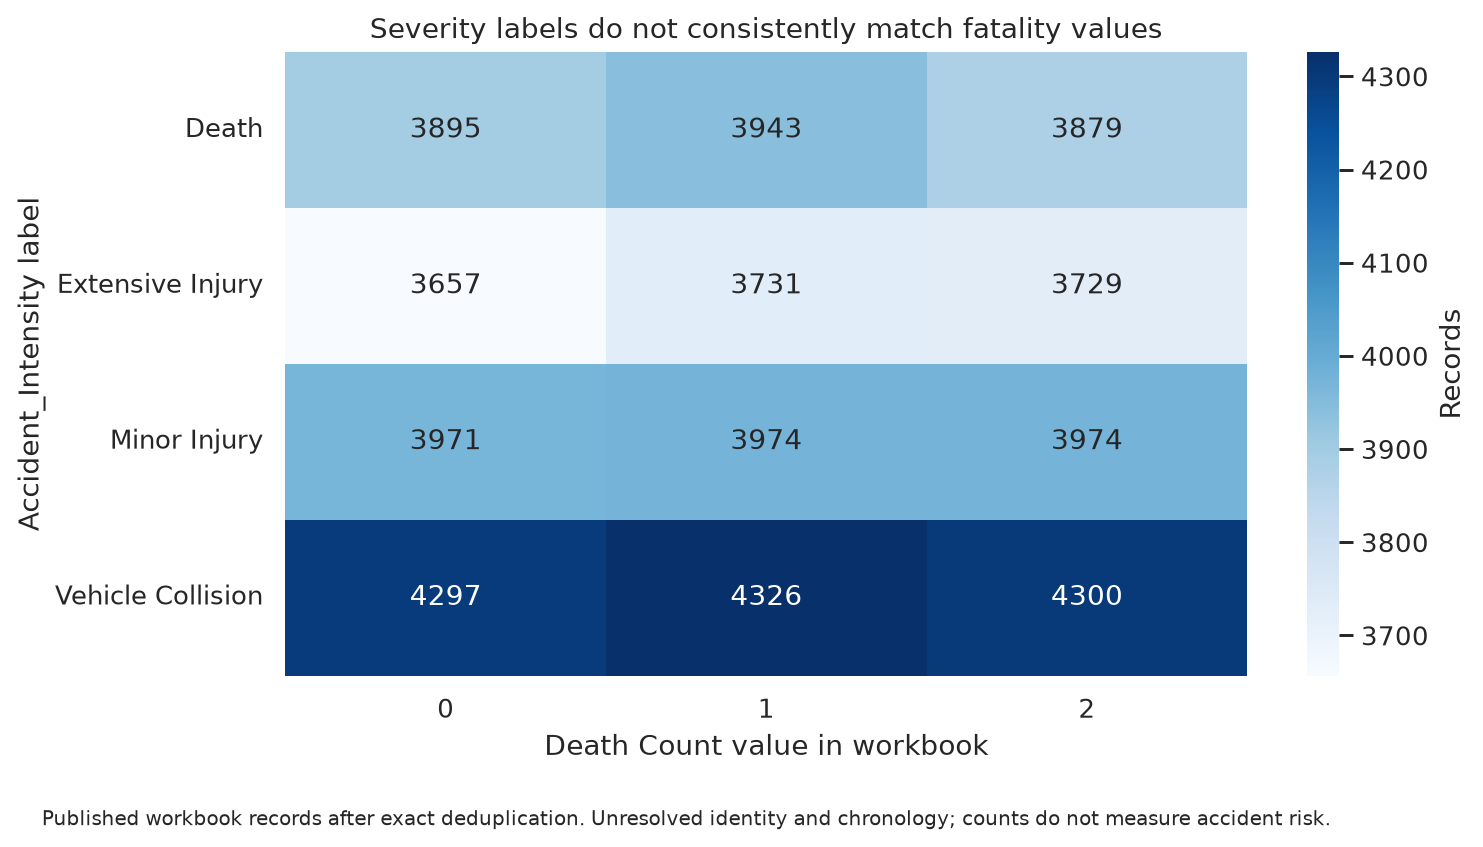

In [4]:
display(
    Image(
        filename=str(REPORTS / "figures/04_severity_fatality_consistency.png"),
        width=900,
    )
)

Death labels appear even where the numeric fatality value is zero. Conversely, positive values occur under other labels. Keep the original severity label and a separately defined positive-count indicator.

## What does a participant count represent?

Join the participant bridge by source_row. One row can mention multiple categories. COUNT(DISTINCT ...) keeps the numerator at source-row grain within each category.

-- Participant rows overlap. Do not add counts or summed fatality values across participants.
SELECT p.participant_type, COUNT(DISTINCT r.source_row) AS records,
 SUM(r.fatal_record) AS fatal_records, AVG(r.fatal_record) AS fatal_record_share
FROM participants p JOIN records r USING(source_row)
GROUP BY p.participant_type ORDER BY records DESC;



,participant_type,records,fatal_records,fatal_record_share
0,Motorcycle,46027,30726,0.667565
1,Truck,45981,30712,0.667928
2,Bus,905,615,0.679558
3,Pedestrian,850,565,0.664706
4,Rickshaw (unspecified),573,395,0.689354


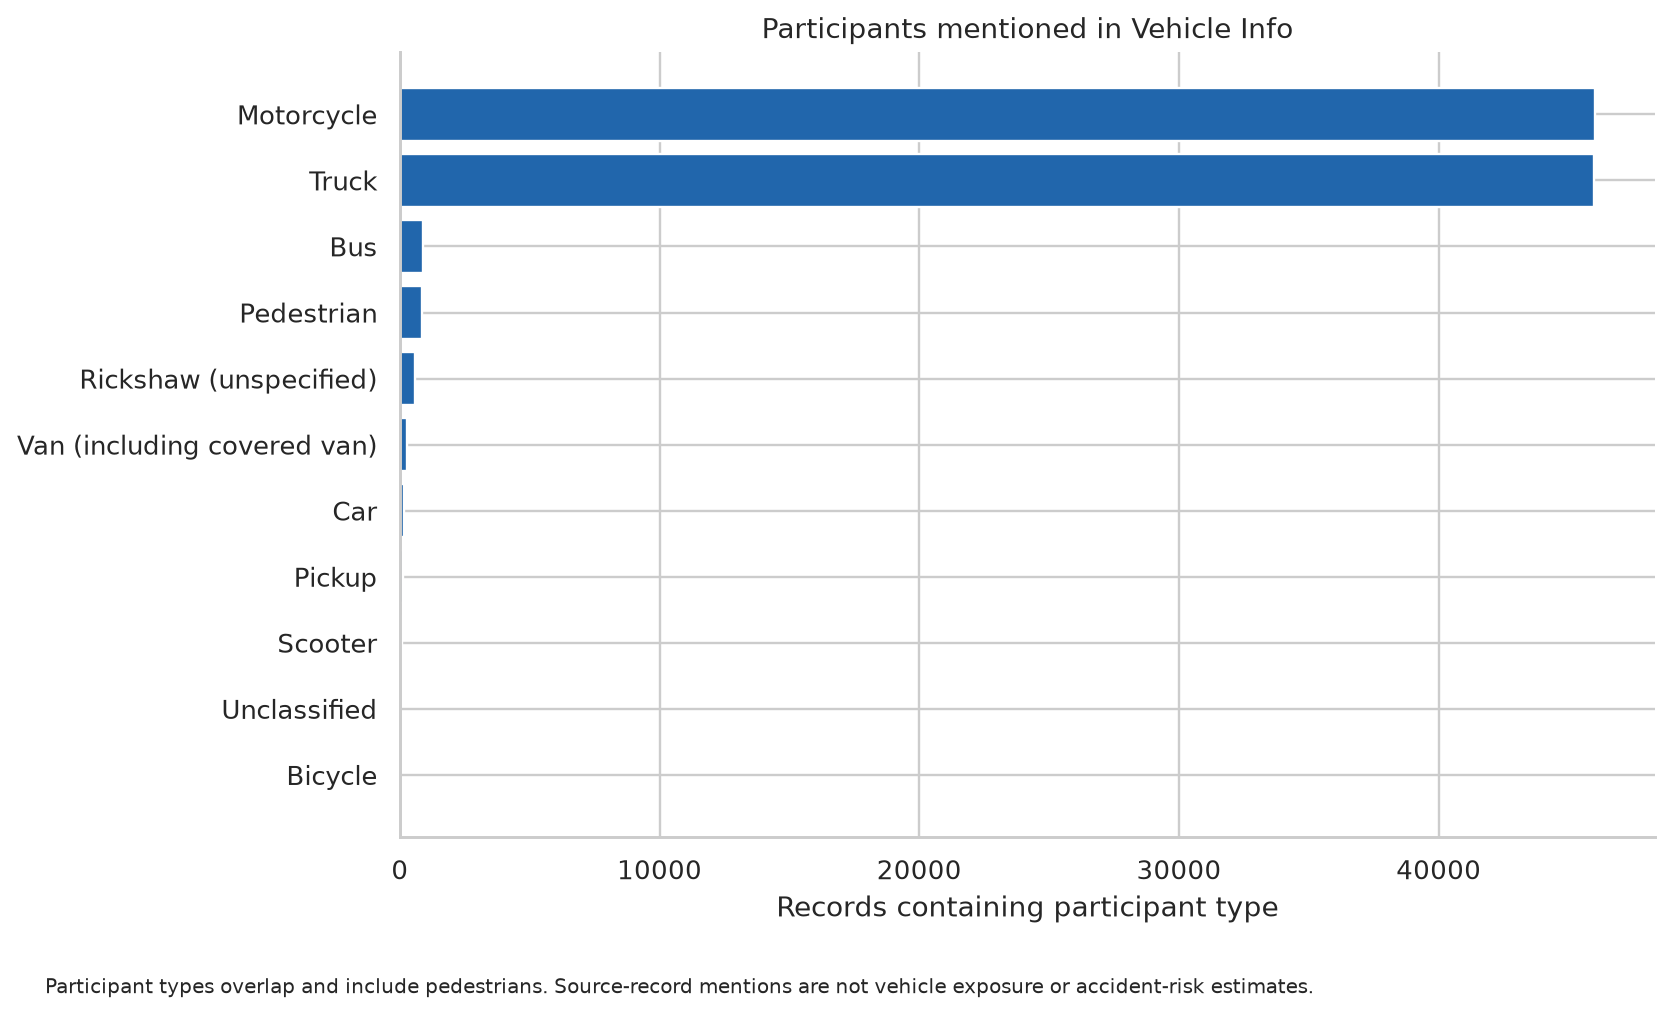

In [5]:
participant_sql = (ROOT / "sql/07_participants.sql").read_text()
print(participant_sql)
with closing(sqlite3.connect(DB_URI, uri=True)) as connection:
    participants = pd.read_sql_query(participant_sql, connection)
display(participants.head(5))
display(Image(filename=str(REPORTS / "figures/05_participant_mentions.png"), width=900))

Motorcycle and truck mentions dominate. Their categories overlap, and neither the row counts nor the within-category shares measure road-user risk.

## Do parallel weather and light fields tell the same story?

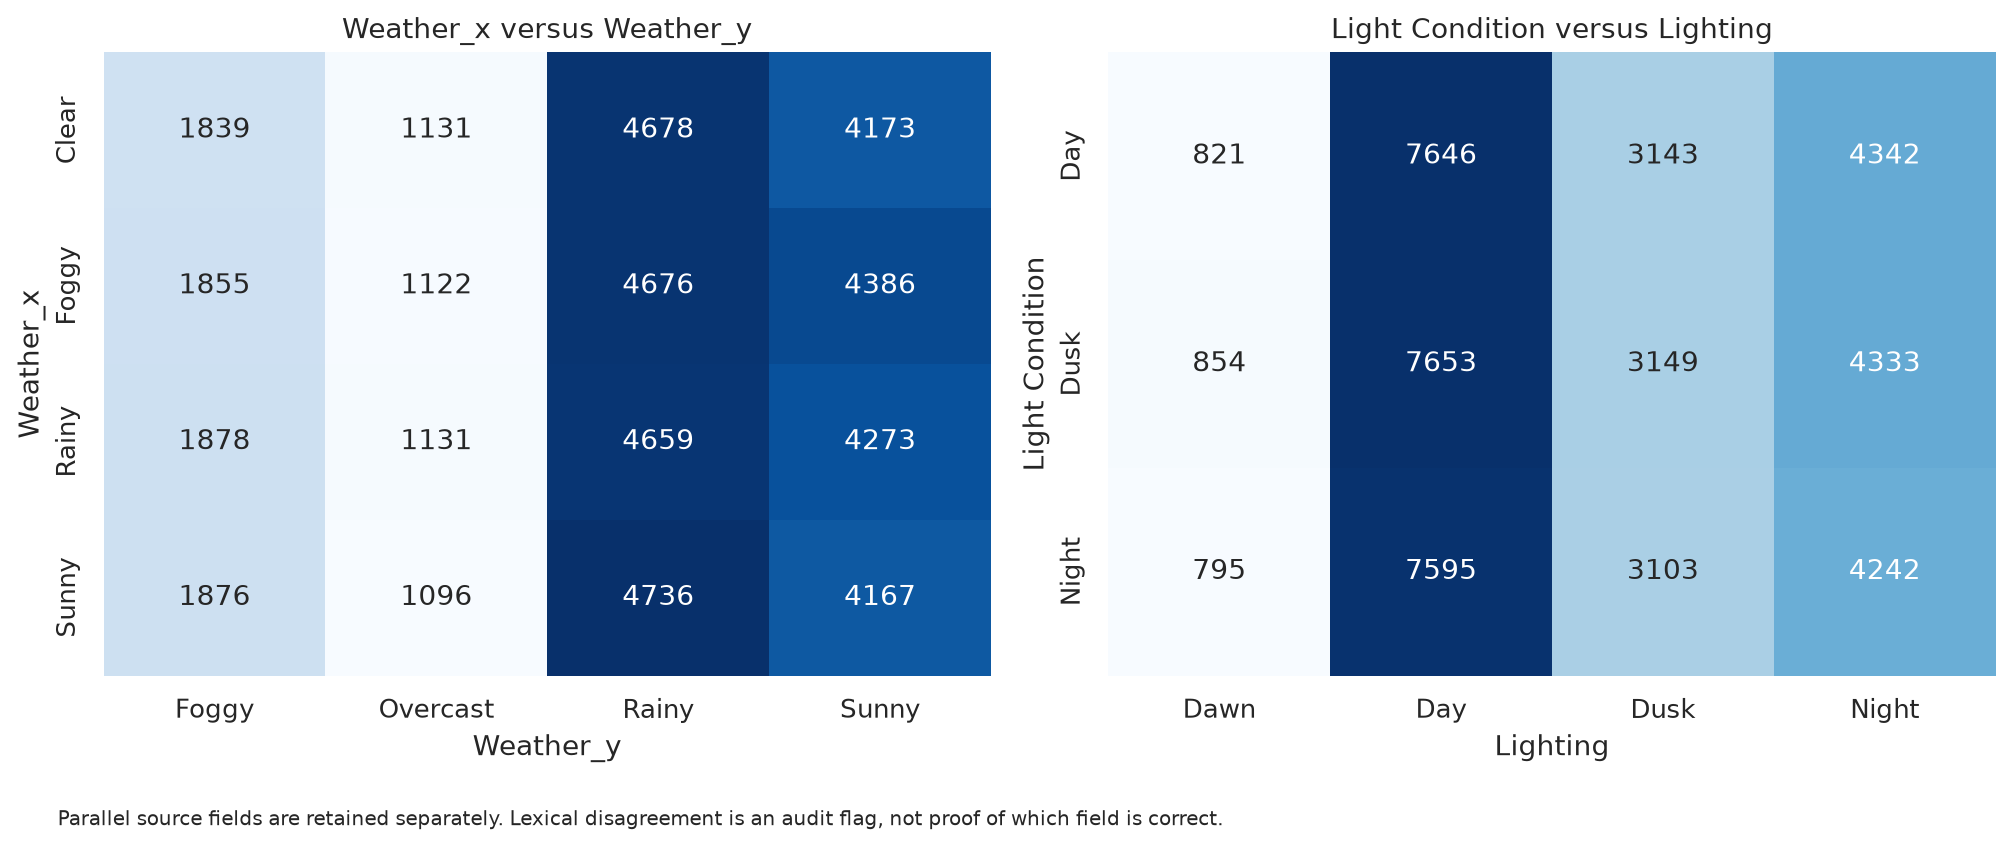

In [6]:
display(
    Image(
        filename=str(REPORTS / "figures/06_parallel_field_disagreements.png"), width=900
    )
)

Weather and light fields frequently disagree. Collapsing them to a single trusted measure would require definitions or source records.

## How concentrated are road categories and coordinates?

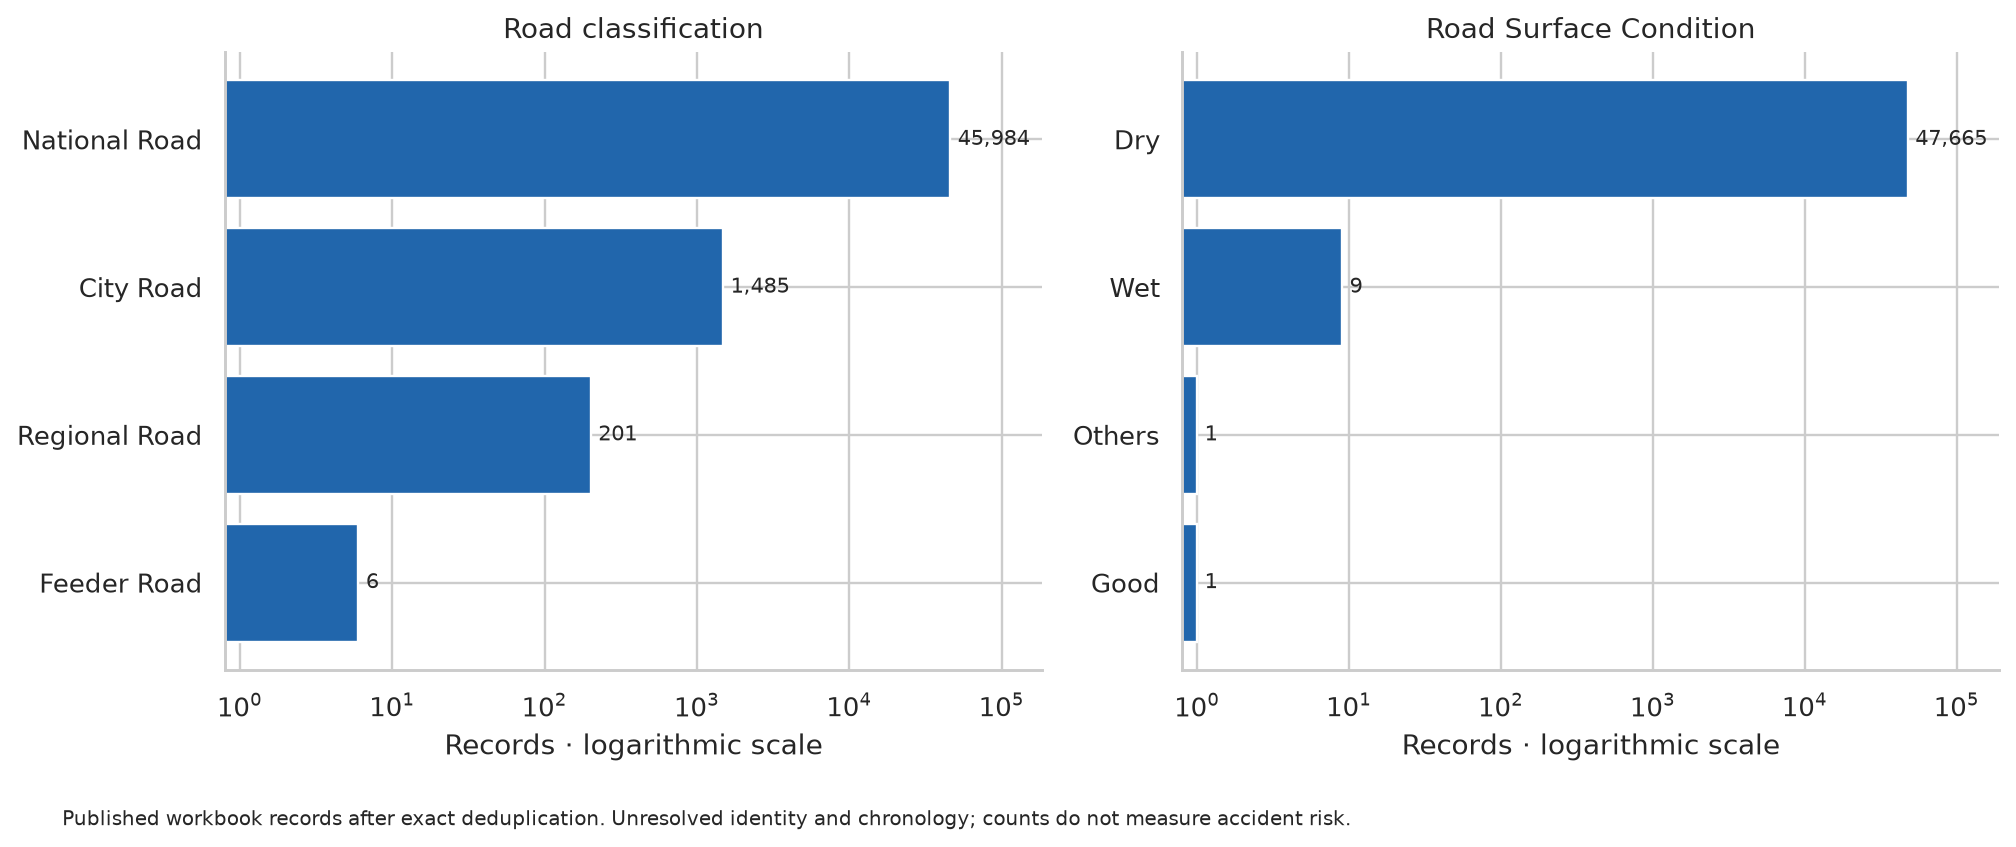

In [7]:
display(Image(filename=str(REPORTS / "figures/07_road_fields.png"), width=900))

National Road dominates the road-class labels. The field describes the workbook’s composition, with broad coverage and reporting practices still unknown.

## Does one coordinate drive the spatial picture?

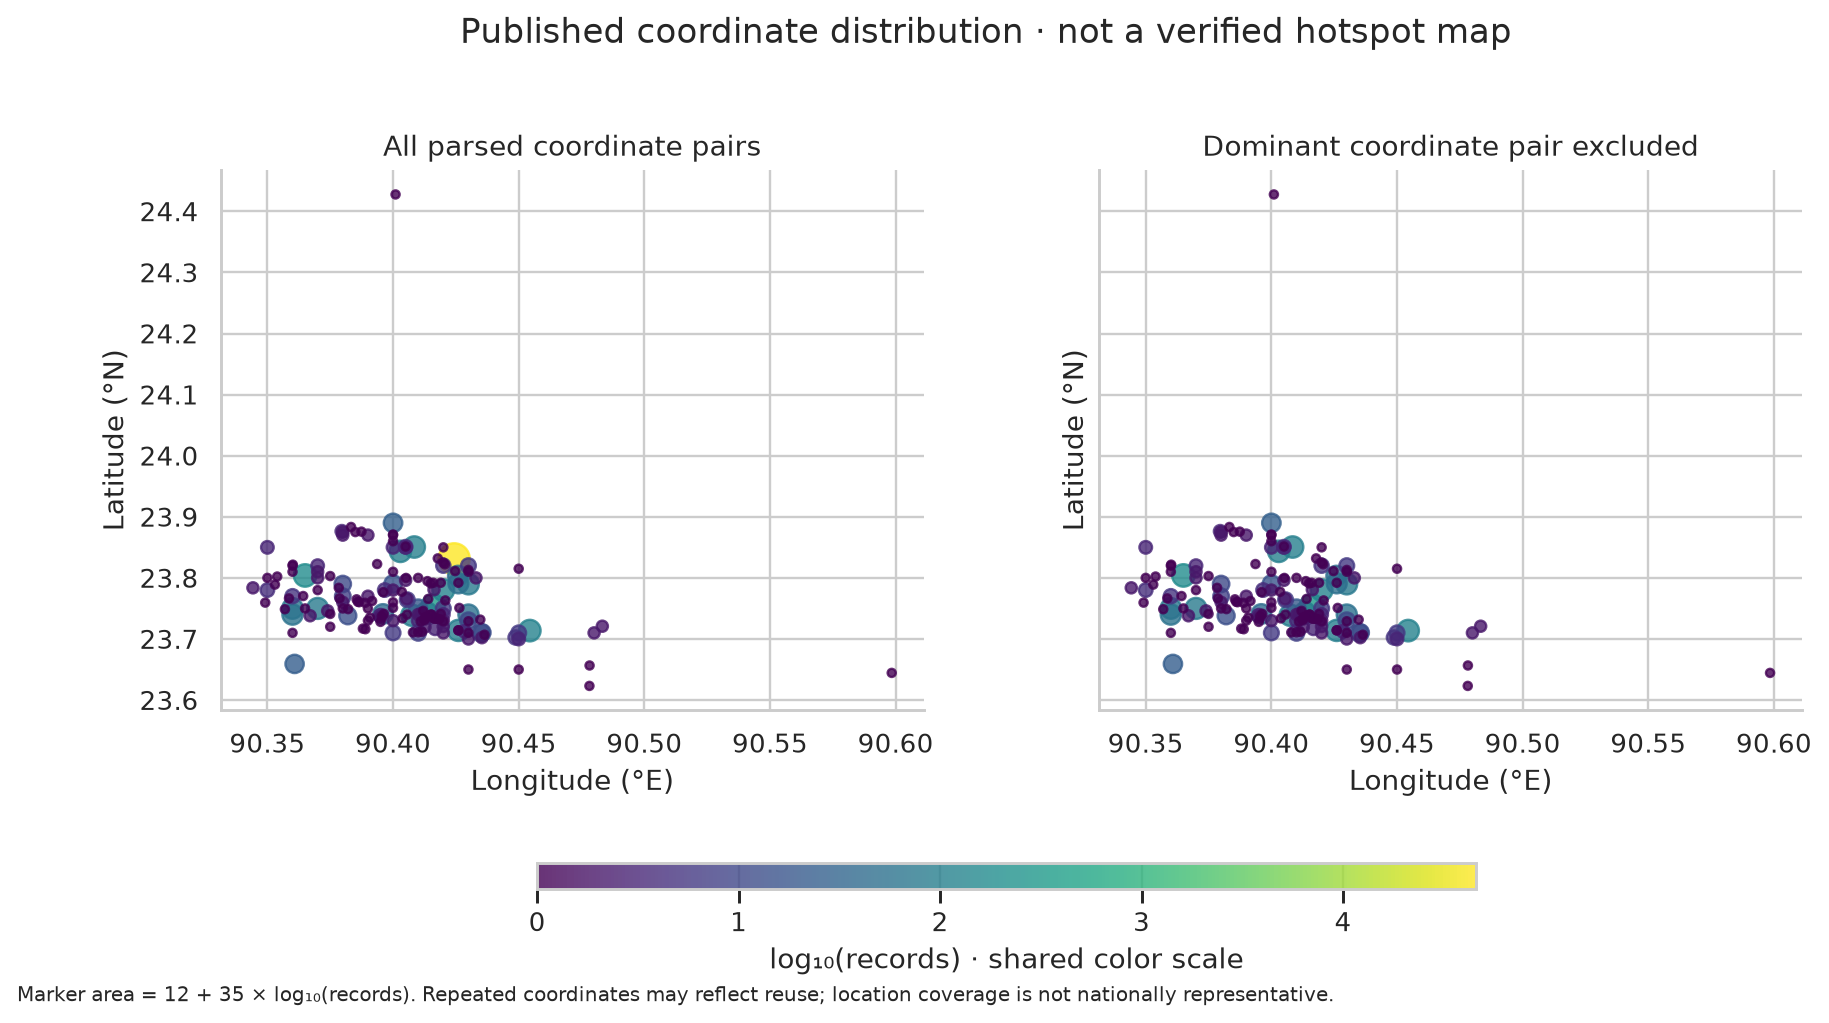

In [8]:
display(Image(filename=str(REPORTS / "figures/08_coordinate_coverage.png"), width=900))

One coordinate pair appears on 45,506 rows. The second view exposes the other observed pairs on a shared color scale. Neither view establishes validated hotspots. Next, test how uncertain identity changes even a narrow comparison of recorded fields.

[Previous](01_source_quality_and_cleaning.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](03_statistics_and_identity_sensitivity.ipynb)